
# SignSense — Model Evaluation & Comparison

## 1. Introduction

This notebook presents the evaluation and comparison of two deep learning models, GRU and LSTM, developed for isolated American Sign Language (ASL) recognition.

The evaluation focuses on:

- Classification performance.
- Model robustness under different input conditions.
- Inference latency and computational performance.
- Performance across different participants.
- Comparison between GRU and LSTM models.

All evaluations use the same fixed test set to ensure a fair comparison between models.

## 2. Imports & Configuration

In [14]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Image

# Project root: SignSense
PROJECT_DIR = Path.cwd().parents[1]

# Results folder at project root
RESULTS_DIR = PROJECT_DIR / "results"

print("Project directory:", PROJECT_DIR)
print("Results directory:", RESULTS_DIR)
print("Results directory exists:", RESULTS_DIR.exists())

Project directory: C:\Users\Dell\PycharmProjects\signsense
Results directory: C:\Users\Dell\PycharmProjects\signsense\results
Results directory exists: True



## 3. Dataset Overview

The SignSense dataset is based on the Google Isolated Sign Language Recognition (Google ISLR) dataset.

The prepared dataset contains 15 isolated ASL words represented by landmark sequences.

The fixed test set is used for all model evaluations to ensure consistency.


In [3]:

N_CLASSES = 15
N_TEST_SAMPLES = 814
N_PARTICIPANTS = 3
SEQUENCE_LENGTH = 30
N_FEATURES = 144

class_names = [
    "hello", "thankyou", "please", "yes", "no",
    "wait", "finish", "where", "go", "home",
    "drink", "book", "airplane", "car", "jump"
]

dataset_info = {
    "Number of classes": N_CLASSES,
    "Test samples": N_TEST_SAMPLES,
    "Test participants": N_PARTICIPANTS,
    "Sequence length": SEQUENCE_LENGTH,
    "Features per frame": N_FEATURES
}

display(pd.DataFrame(
    dataset_info.items(),
    columns=["Property", "Value"]
))

,Property,Value
0,Number of classes,15
1,Test samples,814
2,Test participants,3
3,Sequence length,30
4,Features per frame,144



## 4. Load Evaluation Reports

This section loads the JSON reports generated by the evaluation pipeline.

The notebook does not retrain models or repeat evaluation.


In [4]:

def load_report(model_name):
    report_path = RESULTS_DIR / model_name / f"{model_name}_report.json"

    if not report_path.exists():
        print(f"Report not found: {report_path}")
        return None

    with open(report_path, "r", encoding="utf-8") as f:
        return json.load(f)


gru_report = load_report("gru")
lstm_report = load_report("lstm")

print("GRU report loaded:", gru_report is not None)
print("LSTM report loaded:", lstm_report is not None)


Report not found: C:\Users\Dell\PycharmProjects\signsense\evaluation\notebooks\results\gru\gru_report.json
Report not found: C:\Users\Dell\PycharmProjects\signsense\evaluation\notebooks\results\lstm\lstm_report.json
GRU report loaded: False
LSTM report loaded: False



## 5. Model Performance Comparison

This section compares the classification performance of GRU and LSTM using Accuracy and Macro F1-score.


In [5]:

if gru_report is not None and lstm_report is not None:

    performance = pd.DataFrame({
        "GRU": [
            gru_report["metrics"]["accuracy"],
            gru_report["metrics"]["macro_f1"]
        ],
        "LSTM": [
            lstm_report["metrics"]["accuracy"],
            lstm_report["metrics"]["macro_f1"]
        ]
    }, index=["Accuracy", "Macro F1"])

    display(performance)

    performance.plot(
        kind="bar",
        figsize=(8, 5),
        ylim=(0, 1),
        rot=0
    )

    plt.title("GRU vs LSTM - Classification Performance")
    plt.ylabel("Score")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("Waiting for both real model reports.")


Waiting for both real model reports.



## 6. Confusion Matrices

Confusion matrices provide a detailed view of classification performance across the 15 ASL classes.

They help identify correctly classified samples and class-level prediction errors.


In [6]:

for model_name in ["gru", "lstm"]:

    cm_path = RESULTS_DIR / model_name / f"confusion_matrix_{model_name}.png"

    if cm_path.exists():
        print(f"{model_name.upper()} Confusion Matrix")
        display(Image(filename=str(cm_path)))
    else:
        print(f"Confusion matrix not found for {model_name}.")


Confusion matrix not found for gru.
Confusion matrix not found for lstm.



## 7. Robustness Analysis

This section examines how different input transformations affect model performance.

The evaluation includes:

- Noise injection.
- Frame dropping.
- Left-hand removal.
- Right-hand removal.
- Faster signing sequences.
- Slower signing sequences.

Accuracy and Macro F1 are used to assess the impact of these transformations.


,accuracy,macro_f1,accuracy_drop
original,0.066339,0.021640,0.000000
noise,0.066339,0.021627,0.000000
drop_frames_20,0.065111,0.020669,0.001229
drop_left_hand,0.066339,0.018642,0.000000
drop_right_hand,0.067568,0.021500,-0.001229
faster_1.2,0.062654,0.019093,0.003686
slower_0.8,0.068796,0.025122,-0.002457


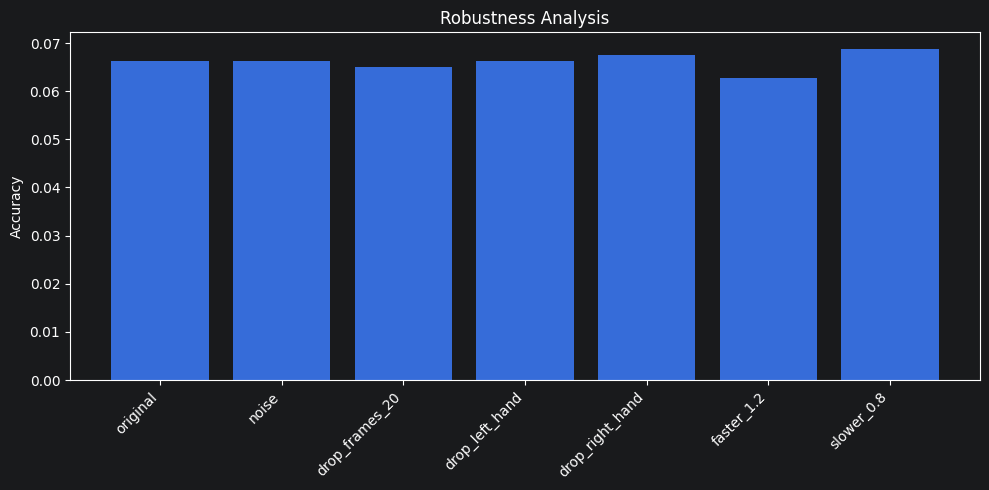

In [19]:


robustness = report["robustness"]

robustness_df = pd.DataFrame.from_dict(
    robustness,
    orient="index"
)

display(robustness_df)

plt.figure(figsize=(10, 5))
plt.bar(
    robustness_df.index,
    robustness_df["accuracy"]
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Accuracy")
plt.title("Robustness Analysis")
plt.tight_layout()
plt.show()




## 8. Participant-level Evaluation

This section investigates model performance across the participants included in the fixed test set.

Participant-level analysis helps identify potential differences in recognition performance between signers.


,Participant,Accuracy
0,25571,0.077253
1,26734,0.068966
2,61333,0.054983


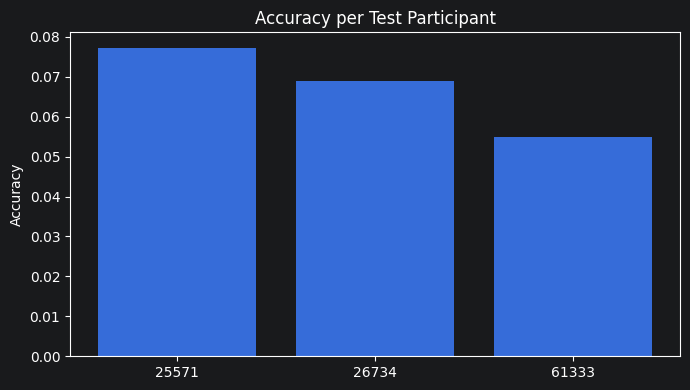

In [20]:


participant_accuracy = report["participant_accuracy"]

participant_df = pd.DataFrame(
    list(participant_accuracy.items()),
    columns=["Participant", "Accuracy"]
)

display(participant_df)

plt.figure(figsize=(7, 4))
plt.bar(
    participant_df["Participant"],
    participant_df["Accuracy"]
)
plt.ylabel("Accuracy")
plt.title("Accuracy per Test Participant")
plt.tight_layout()
plt.show()




## 9. Inference Latency

Inference latency measures the time required by a model to process input samples.

Lower latency indicates faster inference and may be beneficial for real-time sign language recognition.


In [10]:

latency_data = {}

for model_name, report in [
    ("GRU", gru_report),
    ("LSTM", lstm_report)
]:

    if report is not None and "latency" in report:
        latency_data[model_name] = (
            report["latency"]["latency_per_sample_ms"]
        )

if latency_data:
    latency_df = pd.DataFrame(
        latency_data.items(),
        columns=["Model", "Latency (ms/sample)"]
    )

    display(latency_df)

    latency_df.set_index("Model").plot(
        kind="bar",
        legend=False,
        figsize=(7, 4),
        rot=0
    )

    plt.title("Inference Latency Comparison")
    plt.ylabel("Milliseconds per sample")
    plt.tight_layout()
    plt.show()
else:
    print("Waiting for real model latency results.")


Waiting for real model latency results.



## 10. Model Comparison Report

This section loads the final comparison generated by `compare_models.py`.

It presents the paired bootstrap confidence intervals and the overall comparison between the two models.


In [11]:

comparison_path = (
    RESULTS_DIR / "comparison" / "model_comparison.json"
)

if comparison_path.exists():

    with open(comparison_path, "r", encoding="utf-8") as f:
        comparison = json.load(f)

    print("Models:", comparison["models"])
    print("Test samples:", comparison["test_samples"])

    display(pd.DataFrame(comparison["metrics"]).T)

    print("\nPaired Bootstrap Confidence Intervals:")
    display(pd.DataFrame(comparison["paired_bootstrap"]).T)

    print("\nLatency Comparison:")
    display(pd.DataFrame([comparison["latency_ms_per_sample"]]))

else:
    print("Final model comparison is not available yet.")


Final model comparison is not available yet.



## 11. Conclusion

This notebook provides an overview of the evaluation and comparison of GRU and LSTM models for isolated ASL recognition.

The analysis considers classification performance, robustness, participant-level results, and inference latency.

The final conclusions will be updated after evaluating both trained models on the fixed test set.


In [15]:
import json
from pathlib import Path

report_path = RESULTS_DIR / "smoke_test" / "smoke_test_report.json"

with open(report_path, "r", encoding="utf-8") as f:
    report = json.load(f)

print("Report keys:", list(report.keys()))
print(json.dumps(report, indent=2)[:5000])

for key, value in report.items():
    print(f"\n{key}:")
    if isinstance(value, dict):
        print("  Subkeys:", list(value.keys()))
    else:
        print(" ", value)

Report keys: ['model_name', 'test_samples', 'test_participants', 'metrics', 'participant_accuracy', 'hand_frame_analysis', 'robustness', 'latency', 'confusion_matrix']
{
  "model_name": "smoke_test",
  "test_samples": 814,
  "test_participants": [
    25571,
    26734,
    61333
  ],
  "metrics": {
    "accuracy": 0.06633906633906633,
    "macro_precision": 0.01572681728720376,
    "macro_recall": 0.06449044721140054,
    "macro_f1": 0.02164046529038483,
    "top_3_accuracy": 0.20393120393120392,
    "ece": 0.0866723419041247,
    "classification_report": {
      "hello": {
        "precision": 0.0,
        "recall": 0.0,
        "f1-score": 0.0,
        "support": 58.0
      },
      "thankyou": {
        "precision": 0.0,
        "recall": 0.0,
        "f1-score": 0.0,
        "support": 52.0
      },
      "please": {
        "precision": 0.04,
        "recall": 0.017543859649122806,
        "f1-score": 0.024390243902439025,
        "support": 57.0
      },
      "yes": {
        "p